In [1]:
import pandas as pd

reps = pd.read_csv(
    "../results/tables/architecture_representatives.csv"
)

thermophiles = {
    "myceliophthora_thermophila",
    "chaetomium_thermophilum",
    "thielavia_terrestris"
}

reps["thermophile"] = (
    reps["species"]
    .isin(thermophiles)
)
reps["reviewed"] = (
    reps["protein"]
    .str.startswith("sp|")
)
reps.head()

,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed
0,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True,penicillium_oxalicum,3,3,1.0,False,False
1,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True,neurospora_crassa,2,2,1.0,False,True
2,AA1_3_AA1,0,tr|W6Q429|W6Q429_PENRF,True,penicillium_roqueforti,1,1,1.0,False,False
3,AA2_AA5,0,tr|A0A698XLC6|A0A698XLC6_TALPI,True,talaromyces_pinophilus,1,1,1.0,False,False
4,AA8_AA3_1,0,tr|A0A1L9U833|A0A1L9U833_ASPBC,True,aspergillus_brasiliensis,2,2,1.0,False,False


In [2]:
arch = pd.read_csv(
    "../results/tables/architecture_summary.csv"
)

arch = arch.rename(columns={
    "domain_architecture": "architecture",
    "proteins": "architecture_proteins",
    "species": "architecture_species",
    "thermophile_species": "architecture_thermophiles"
})
arch["architecture"] = (
    arch["architecture"]
    .str.replace(" + ", "_", regex=False)
)

arch.head()

,architecture,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase
0,GH72_CBM43,48,23,1,True,True
1,GH71_CBM24,34,19,1,True,True
2,GH15_CBM20,30,20,2,True,False
3,GH54_CBM42,28,19,1,True,True
4,AA8_AA3_1,27,15,3,False,False


In [3]:

reps = reps.merge(
    arch,
    on="architecture",
    how="left"
)


reps.head()

,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase
0,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True,penicillium_oxalicum,3,3,1.0,False,False,5,5,0,True,False
1,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True,neurospora_crassa,2,2,1.0,False,True,5,5,0,True,False
2,AA1_3_AA1,0,tr|W6Q429|W6Q429_PENRF,True,penicillium_roqueforti,1,1,1.0,False,False,1,1,0,False,False
3,AA2_AA5,0,tr|A0A698XLC6|A0A698XLC6_TALPI,True,talaromyces_pinophilus,1,1,1.0,False,False,1,1,0,False,False
4,AA8_AA3_1,0,tr|A0A1L9U833|A0A1L9U833_ASPBC,True,aspergillus_brasiliensis,2,2,1.0,False,False,27,15,3,False,False


In [4]:
reps["cluster_fraction"] = (
    reps["cluster_size"]
    / reps["architecture_proteins"]
)

reps["species_fraction"] = (
    reps["species_in_cluster"]
    / reps["architecture_species"]
)
reps.sort_values(
    [
        "species_in_cluster",
        "cluster_size"
    ],
    ascending=False
).head(20)
thermo = reps[
    reps["thermophile"]
]

thermo.sort_values(
    "cluster_size",
    ascending=False
)
novel = reps[
    ~reps["reviewed"]
]

novel.sort_values(
    "cluster_size",
    ascending=False
)
priority = reps[
    (reps["thermophile"])
    &
    (~reps["reviewed"])
]

priority.sort_values(
    [
        "species_in_cluster",
        "cluster_size"
    ],
    ascending=False
)


,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase,cluster_fraction
8,AA8_AA3_1,4,tr|G0S434|G0S434_CHATD,True,chaetomium_thermophilum,5,5,0.333333,True,False,27,15,3,False,False,0.185185
186,GH7_CBM1,2,tr|G2Q665|G2Q665_THET4,True,myceliophthora_thermophila,3,3,0.428571,True,False,11,7,2,True,True,0.272727
41,GH13_1_CBM20,4,tr|G2Q1W3|G2Q1W3_THET4,True,myceliophthora_thermophila,2,2,0.142857,True,False,16,14,2,True,False,0.125000
17,AA8_AA3_1,13,tr|G0S3B0|G0S3B0_CHATD,True,chaetomium_thermophilum,1,1,0.066667,True,False,27,15,3,False,False,0.037037
44,GH13_1_CBM20,7,tr|G2R2D7|G2R2D7_THETT,True,thielavia_terrestris,1,1,0.071429,True,False,16,14,2,True,False,0.062500
50,GH15_CBM20,0,tr|G2RHN1|G2RHN1_THETT,True,thielavia_terrestris,1,1,0.050000,True,False,30,20,2,True,False,0.033333
56,GH15_CBM20,6,tr|G2QUZ8|G2QUZ8_THETT,True,thielavia_terrestris,1,1,0.050000,True,False,30,20,2,True,False,0.033333
59,GH15_CBM20,9,tr|G2QPS0|G2QPS0_THET4,True,myceliophthora_thermophila,1,1,0.050000,True,False,30,20,2,True,False,0.033333
75,GH30_7_GH30,0,tr|G0S6Q3|G0S6Q3_CHATD,True,chaetomium_thermophilum,1,1,1.000000,True,False,1,1,1,False,False,1.000000
87,GH43_14_CBM91,1,tr|G2QAJ6|G2QAJ6_THET4,True,myceliophthora_thermophila,1,1,0.071429,True,False,19,14,2,True,False,0.052632


In [5]:
reps[
    [
        "architecture",
        "protein",
        "species",
        "cluster_size",
        "species_in_cluster",
        "thermophile",
        "reviewed"
    ]
].head()

,architecture,protein,species,cluster_size,species_in_cluster,thermophile,reviewed
0,AA13_CBM20,tr|S8AKS0|S8AKS0_PENO1,penicillium_oxalicum,3,3,False,False
1,AA13_CBM20,sp|Q7SCE9|AA13_NEUCR,neurospora_crassa,2,2,False,True
2,AA1_3_AA1,tr|W6Q429|W6Q429_PENRF,penicillium_roqueforti,1,1,False,False
3,AA2_AA5,tr|A0A698XLC6|A0A698XLC6_TALPI,talaromyces_pinophilus,1,1,False,False
4,AA8_AA3_1,tr|A0A1L9U833|A0A1L9U833_ASPBC,aspergillus_brasiliensis,2,2,False,False


In [6]:
reps.sort_values(
    ["species_in_cluster", "cluster_size"],
    ascending=False
).head(20)

,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase,cluster_fraction
119,GH54_CBM42,1,tr|G9NYH4|G9NYH4_HYPAI,True,trichoderma_atroviride,20,13,0.684211,False,False,28,19,1,True,True,0.714286
8,AA8_AA3_1,4,tr|G0S434|G0S434_CHATD,True,chaetomium_thermophilum,5,5,0.333333,True,False,27,15,3,False,False,0.185185
55,GH15_CBM20,5,tr|A0A364L476|A0A364L476_TALAM,True,talaromyces_amestolkiae,5,5,0.250000,False,False,30,20,2,True,False,0.166667
120,GH54_CBM42,2,sp|O74288|ABFB_EMENI,True,aspergillus_nidulans,5,5,0.263158,False,True,28,19,1,True,True,0.178571
123,GH5_4_CBM46,0,tr|S7ZX22|S7ZX22_PENO1,True,penicillium_oxalicum,5,5,1.000000,False,False,5,5,0,True,True,1.000000
22,CBM35_GH26,0,sp|G2Q4H7|MA26A_THET4,True,myceliophthora_thermophila,4,4,1.000000,True,True,4,4,2,True,False,1.000000
57,GH15_CBM20,7,tr|G0R866|G0R866_HYPJQ,True,trichoderma_reesei,4,4,0.200000,False,False,30,20,2,True,False,0.133333
149,GH71_CBM24,23,tr|G9NRY6|G9NRY6_HYPAI,True,trichoderma_atroviride,4,4,0.210526,False,False,34,19,1,True,True,0.117647
156,GH72_CBM43,1,sp|B0XVI5|GEL4_ASPFC,True,aspergillus_fumigatus,4,4,0.173913,False,True,48,23,1,True,True,0.083333
158,GH72_CBM43,3,tr|G9NIE1|G9NIE1_HYPAI,True,trichoderma_atroviride,4,4,0.173913,False,False,48,23,1,True,True,0.083333


In [7]:
# Biomass-related representatives
reps[reps["has_cellulase"]]



,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase,cluster_fraction
19,AA9_CBM1,0,sp|B2B629|LP9A_PODAN,True,podospora_anserina,1,1,1.000000,False,True,1,1,0,True,True,1.000000
20,CBM1_GH10,0,tr|B2AMK1|B2AMK1_PODAN,True,podospora_anserina,1,1,1.000000,False,False,1,1,0,True,True,1.000000
21,CBM1_GH45_1,0,tr|A0A9P7BX53|A0A9P7BX53_RHIOR,True,rhizopus_oryzae,1,1,1.000000,False,False,1,1,0,True,True,1.000000
31,GH10_CBM1,0,tr|B2AFS1|B2AFS1_PODAN,True,podospora_anserina,3,3,0.500000,False,False,6,6,2,True,True,0.500000
32,GH10_CBM1,1,tr|A0A364LCP8|A0A364LCP8_TALAM,True,talaromyces_amestolkiae,1,1,0.166667,False,False,6,6,2,True,True,0.166667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,GH7_CBM1,1,tr|A0A364L451|A0A364L451_TALAM,True,talaromyces_amestolkiae,1,1,0.142857,False,False,11,7,2,True,True,0.090909
186,GH7_CBM1,2,tr|G2Q665|G2Q665_THET4,True,myceliophthora_thermophila,3,3,0.428571,True,False,11,7,2,True,True,0.272727
187,GH7_CBM1,3,tr|A0A8H6ZYZ4|A0A8H6ZYZ4_PLEOS,True,pleurotus_ostreatus,2,1,0.142857,False,False,11,7,2,True,True,0.181818
188,GH7_CBM1,4,tr|A0A5M3Z9H2|A0A5M3Z9H2_ASPTE,True,aspergillus_terreus,2,2,0.285714,False,False,11,7,2,True,True,0.181818


In [8]:
# Thermophile representatives
reps[reps["thermophile"]]

,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase,cluster_fraction
8,AA8_AA3_1,4,tr|G0S434|G0S434_CHATD,True,chaetomium_thermophilum,5,5,0.333333,True,False,27,15,3,False,False,0.185185
17,AA8_AA3_1,13,tr|G0S3B0|G0S3B0_CHATD,True,chaetomium_thermophilum,1,1,0.066667,True,False,27,15,3,False,False,0.037037
22,CBM35_GH26,0,sp|G2Q4H7|MA26A_THET4,True,myceliophthora_thermophila,4,4,1.000000,True,True,4,4,2,True,False,1.000000
41,GH13_1_CBM20,4,tr|G2Q1W3|G2Q1W3_THET4,True,myceliophthora_thermophila,2,2,0.142857,True,False,16,14,2,True,False,0.125000
44,GH13_1_CBM20,7,tr|G2R2D7|G2R2D7_THETT,True,thielavia_terrestris,1,1,0.071429,True,False,16,14,2,True,False,0.062500
50,GH15_CBM20,0,tr|G2RHN1|G2RHN1_THETT,True,thielavia_terrestris,1,1,0.050000,True,False,30,20,2,True,False,0.033333
56,GH15_CBM20,6,tr|G2QUZ8|G2QUZ8_THETT,True,thielavia_terrestris,1,1,0.050000,True,False,30,20,2,True,False,0.033333
59,GH15_CBM20,9,tr|G2QPS0|G2QPS0_THET4,True,myceliophthora_thermophila,1,1,0.050000,True,False,30,20,2,True,False,0.033333
75,GH30_7_GH30,0,tr|G0S6Q3|G0S6Q3_CHATD,True,chaetomium_thermophilum,1,1,1.000000,True,False,1,1,1,False,False,1.000000
87,GH43_14_CBM91,1,tr|G2QAJ6|G2QAJ6_THET4,True,myceliophthora_thermophila,1,1,0.071429,True,False,19,14,2,True,False,0.052632


In [9]:
from Bio import SeqIO
import pandas as pd
import os


# -------------------------
# Get lengths from FASTAs
# -------------------------

fasta_dir = "../results/architecture_fastas"

lengths = {}

for fasta_file in os.listdir(fasta_dir):

    if not fasta_file.endswith(".fasta"):
        continue

    fasta_path = os.path.join(
        fasta_dir,
        fasta_file
    )

    for record in SeqIO.parse(fasta_path, "fasta"):

        lengths[record.id] = len(record.seq)

print(f"Loaded lengths for {len(lengths)} proteins")

Loaded lengths for 312 proteins


In [10]:
reps["length"] = reps["protein"].map(lengths)

reps["length"].isna().sum()

np.int64(0)

In [11]:
cols = [
    "architecture",
    "cluster",
    "protein",
    "species",
    "length",

    "cluster_size",
    "species_in_cluster",
    "species_fraction",

    "thermophile",
    "reviewed",

    "architecture_proteins",
    "architecture_species",
    "architecture_thermophiles",

    "has_cbm",
    "has_cellulase",

    "cluster_fraction"
]

reps = reps[cols]

In [12]:
reps.to_csv(
    "../results/tables/representative_candidates.csv",
    index=False
)

print(reps.shape)
reps.head()

(191, 16)


,architecture,cluster,protein,species,length,cluster_size,species_in_cluster,species_fraction,thermophile,reviewed,architecture_proteins,architecture_species,architecture_thermophiles,has_cbm,has_cellulase,cluster_fraction
0,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,penicillium_oxalicum,403,3,3,0.600000,False,False,5,5,0,True,False,0.600000
1,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,neurospora_crassa,385,2,2,0.400000,False,True,5,5,0,True,False,0.400000
2,AA1_3_AA1,0,tr|W6Q429|W6Q429_PENRF,penicillium_roqueforti,587,1,1,1.000000,False,False,1,1,0,False,False,1.000000
3,AA2_AA5,0,tr|A0A698XLC6|A0A698XLC6_TALPI,talaromyces_pinophilus,1672,1,1,1.000000,False,False,1,1,0,False,False,1.000000
4,AA8_AA3_1,0,tr|A0A1L9U833|A0A1L9U833_ASPBC,aspergillus_brasiliensis,934,2,2,0.133333,False,False,27,15,3,False,False,0.074074


In [13]:
reps.sort_values(
    "length",
    ascending=False
)[
    [
        "architecture",
        "protein",
        "species",
        "length"
    ]
].head(20)

,architecture,protein,species,length
71,GH18_CBM24,tr|A0A364L601|A0A364L601_TALAM,talaromyces_amestolkiae,2159
126,GH71_CBM24,tr|Q7RV24|Q7RV24_NEUCR,neurospora_crassa,1736
127,GH71_CBM24,tr|Q2GM42|Q2GM42_CHAGB,chaetomium_globosum,1722
3,AA2_AA5,tr|A0A698XLC6|A0A698XLC6_TALPI,talaromyces_pinophilus,1672
128,GH71_CBM24,tr|S7ZL85|S7ZL85_PENO1,penicillium_oxalicum,1619
72,GH18_CBM24,tr|A0A2T4A6I8|A0A2T4A6I8_TRIHA,trichoderma_harzianum,1523
154,GH71_CBM24_CBM24,tr|A0A364KXE8|A0A364KXE8_TALAM,talaromyces_amestolkiae,1466
80,GH32_CBM38_GH32,tr|A0A478ECL0|A0A478ECL0_TALPI,talaromyces_pinophilus,1395
182,GH79_CBM67_GH78,tr|A0A5M3YUF2|A0A5M3YUF2_ASPTE,aspergillus_terreus,1259
129,GH71_CBM24,tr|B0Y904|B0Y904_ASPFC,aspergillus_fumigatus,1254


In [14]:
architecture_summary = (
    reps
    .groupby("architecture")
    .agg({
        "architecture_proteins": "first",
        "architecture_species": "first",
        "cluster_size": "max",
        "species_in_cluster": "max",
        "thermophile": "sum",
        "reviewed": "sum",
        "has_cbm": "first",
        "has_cellulase": "first"
    })
    .reset_index()
)

architecture_summary

,architecture,architecture_proteins,architecture_species,cluster_size,species_in_cluster,thermophile,reviewed,has_cbm,has_cellulase
0,AA13_CBM20,5,5,3,3,0,1,True,False
1,AA1_3_AA1,1,1,1,1,0,0,False,False
2,AA2_AA5,1,1,1,1,0,0,False,False
3,AA8_AA3_1,27,15,5,5,2,0,False,False
4,AA9_CBM1,1,1,1,1,0,1,True,True
5,CBM1_GH10,1,1,1,1,0,0,True,True
6,CBM1_GH45_1,1,1,1,1,0,0,True,True
7,CBM35_GH26,4,4,4,4,1,1,True,False
8,CBM38_GH32,2,2,1,1,0,0,True,False
9,CBM87_CE18,3,3,1,1,0,0,True,False


In [15]:
print("Representative proteins:", len(reps))
print("Architectures:", reps["architecture"].nunique())
print("Species:", reps["species"].nunique())

print()

print("Thermophile representatives:",
      reps["thermophile"].sum())

print("Reviewed representatives:",
      reps["reviewed"].sum())

print("CBM-containing representatives:",
      reps["has_cbm"].sum())

print("Cellulase-related representatives:",
      reps["has_cellulase"].sum())

Representative proteins: 191
Architectures: 47
Species: 29

Thermophile representatives: 18
Reviewed representatives: 7
CBM-containing representatives: 166
Cellulase-related representatives: 82


In [16]:
conserved = reps[
    reps["species_in_cluster"] >= 3
].sort_values(
    ["species_in_cluster", "cluster_size"],
    ascending=False
)

thermo = reps[
    reps["thermophile"]
].sort_values(
    ["cluster_size", "species_in_cluster"],
    ascending=False
)

cellulase = reps[
    reps["has_cellulase"]
].sort_values(
    ["species_in_cluster", "cluster_size"],
    ascending=False
)

rare = reps[
    reps["architecture_proteins"] == 1
].sort_values("architecture")

reviewed = reps[
    reps["reviewed"]
].sort_values(
    ["species_in_cluster", "cluster_size"],
    ascending=False
)

In [17]:
outdir = "../results/tables"

conserved.to_csv(
    f"{outdir}/conserved_candidates.csv",
    index=False
)

thermo.to_csv(
    f"{outdir}/thermophile_candidates.csv",
    index=False
)

cellulase.to_csv(
    f"{outdir}/cellulase_candidates.csv",
    index=False
)

rare.to_csv(
    f"{outdir}/rare_architectures.csv",
    index=False
)

reviewed.to_csv(
    f"{outdir}/reviewed_candidates.csv",
    index=False
)

In [18]:
summary = pd.DataFrame({

    "Candidate_set": [

        "All representatives",
        "Conserved families",
        "Thermophile candidates",
        "Cellulase-related",
        "Reviewed proteins",
        "Rare architectures"

    ],

    "Representatives": [

        len(reps),
        len(conserved),
        len(thermo),
        len(cellulase),
        len(reviewed),
        len(rare)

    ]

})

summary

,Candidate_set,Representatives
0,All representatives,191
1,Conserved families,27
2,Thermophile candidates,18
3,Cellulase-related,82
4,Reviewed proteins,7
5,Rare architectures,22


In [19]:
summary.to_csv(
    "../results/tables/candidate_summary.csv",
    index=False
)

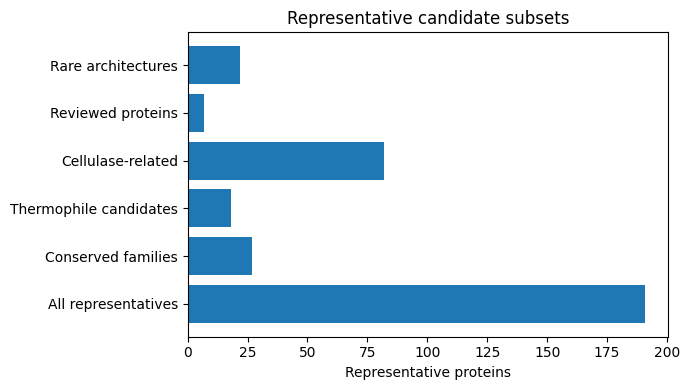

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))

plt.barh(
    summary["Candidate_set"],
    summary["Representatives"]
)

plt.xlabel("Representative proteins")
plt.ylabel("")
plt.title("Representative candidate subsets")

plt.tight_layout()

plt.savefig(
    "../results/figures/candidate_subsets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

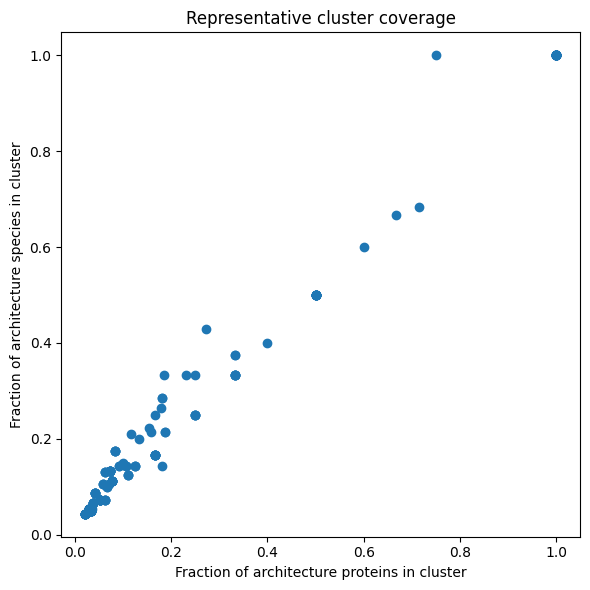

In [21]:
plt.figure(figsize=(6,6))

plt.scatter(

    reps["cluster_fraction"],
    reps["species_fraction"]

)

plt.xlabel("Fraction of architecture proteins in cluster")

plt.ylabel("Fraction of architecture species in cluster")

plt.title("Representative cluster coverage")

plt.tight_layout()

plt.savefig(
    "../results/figures/cluster_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()